In [1]:
!pip install seaborn

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [330]:
conn = sqlite3.connect('customer_churn_aug.db')

sql_query = """
     SELECT name FROM sqlite_master
     WHERE type = 'table';

"""
tables=pd.read_sql(sql_query, conn)
#create database from each tables
for table_name in tables['name']:
    df= pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

conn.close()
    


Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [336]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00


In [332]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [333]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [334]:
#rename column name
df_db_customer.rename(columns = {'name' :'customer_name'}, inplace = True)


In [335]:
df_db_customer.drop(df_db_customer.columns[-2:],axis=1, inplace= True)

In [339]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     121 non-null    object        
 1   customer_name  121 non-null    object        
 2   country        118 non-null    object        
 3   state          121 non-null    object        
 4   gender         121 non-null    object        
 5   dob            121 non-null    datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 5.8+ KB


In [338]:
df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [340]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
...,...,...,...,...,...,...
116,1095-VPTAC,Rohit95,India,UP,Male,1994-09-25
117,1096-JVDCH,Neha96,India,MP,Male,1976-11-25
118,1097-DKABL,Isha97,India,Karnataka,Male,1999-08-27
119,1098-EYVKU,Rahul98,India,Karnataka,Male,1987-12-06


In [343]:
df_db_customer['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [342]:
df_db_customer['gender']=df_db_customer['gender'].replace({'Men': 'Male', 'Women':'Female'})

In [346]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [345]:
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [347]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               121 non-null    object 
 1   subscription_start_date  121 non-null    object 
 2   subscription_type        121 non-null    object 
 3   renewal_date             121 non-null    object 
 4   plan_type                121 non-null    object 
 5   contract_type            121 non-null    object 
 6   cancellation_date        13 non-null     object 
 7   cancellation_reason      13 non-null     object 
 8   monthly_charges          121 non-null    float64
 9   cltv                     121 non-null    int64  
 10  churn_score              121 non-null    int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 10.5+ KB


In [348]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               121 non-null    object        
 1   subscription_start_date  121 non-null    datetime64[ns]
 2   subscription_type        121 non-null    object        
 3   renewal_date             121 non-null    datetime64[ns]
 4   plan_type                121 non-null    object        
 5   contract_type            121 non-null    object        
 6   cancellation_date        13 non-null     datetime64[ns]
 7   cancellation_reason      13 non-null     object        
 8   monthly_charges          121 non-null    float64       
 9   cltv                     121 non-null    int64         
 10  churn_score              121 non-null    int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 10.5+ KB


In [354]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      60 non-null     object        
 1   complaint_date  60 non-null     datetime64[ns]
 2   escalations     60 non-null     object        
 3   csat_score      60 non-null     int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 2.0+ KB


In [351]:
df_db_support.drop(columns=['col_1', 'comment'], inplace= True)

In [353]:
df_db_support['complaint_date']= pd.to_datetime(df_db_support['complaint_date'])

In [374]:
#Feature engineering and data analysis
#Adding New column 'Churn_flag'

df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)

In [375]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [378]:
df=(df_db_subscription
    .merge(df_db_customer, on= 'customerid', how='left' )
    .merge(df_db_support, on= 'customerid', how='left' ))

In [379]:
df.shape

(121, 21)

In [376]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint_count
39,1056-HBUOS,2020-02-20,No,4,1
24,1029-XKVUO,2020-05-16,No,5,1
20,1023-KQFYK,2021-01-28,No,5,1
51,1081-HEODD,2021-02-05,No,4,1
15,1013-CSKFL,2021-03-02,No,3,1


In [377]:
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep='last')


In [365]:
df_db_support.shape

(58, 5)

In [380]:
df.to_csv('exported_churn_aug.csv', index=False)

In [381]:
#churn rate
churn_rate = df['churn_flag'].mean()*100
print("churn rate =",round(churn_rate, 2),"%")

churn rate = 10.74 %


In [382]:
#retention rate
retention_rate = 100 - churn_rate
print("retention rate =", round(retention_rate, 2),"%")

retention rate = 89.26 %


In [421]:
#churn rate within each plan type
churn_by_plan=(df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           14.29
1   Premium            6.98
2  Standard           11.11


In [441]:
#churn rate by state
churn_by_state = (
    df[df['churn_flag'] == 1]
      .groupby('state').size().div(df[df['churn_flag'] == 1].shape[0]).mul(100)
      .round(2).reset_index(name='percentage')
)

print(churn_by_state)

         state  percentage
0        Delhi       15.38
1    Karnataka       30.77
2  Maharashtra        7.69
3    Meghalaya       15.38
4       Punjab        7.69
5    Telangana        7.69
6           UP       15.38


In [422]:
#churn costumer percentage by plan type
churn_distribution = (
    df[df['churn_flag'] == 1].groupby('plan_type').size().div(df[df['churn_flag'] == 1].shape[0])
      .mul(100).round(2)
      .reset_index(name='percentage')
)

print(churn_distribution)

  plan_type  percentage
0     Basic       46.15
1   Premium       23.08
2  Standard       30.77


In [423]:
#average revenue per user
arpu=df['monthly_charges'].mean()
print("ARPU =", round(arpu,2))

ARPU = 525.59


In [424]:
#average customer tenure
today = pd.Timestamp.now().normalize()  # Today's date at 00:00:00  # Today's date at 00:00:00
df['tenure_days'] = np.where(
    df['cancellation_date'].isna(),
    (today - df['subscription_start_date']).dt.days,
    (df['cancellation_date'] - df['subscription_start_date']).dt.days
)
avg_tenure= df['tenure_days'].mean()
print("Average Tenure days =", round(avg_tenure, 0))

Average Tenure days = 1576.0


In [425]:
#revenure loss from churn users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs in 'K') =", round(revenue_at_risk, 2))

Revenue at Risk (Rs in 'K') = 4166.94


In [428]:
#Escalation Rate
Escalation_rate = (df['escalations']== 1).mean()*100
print("Escalation Rate =", round(Escalation_rate, 2),"%")

Escalation Rate = 3.31 %


In [388]:
#Average Complaint per user
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Average Complaint per user =", round(avg_complaints, 2))

Average Complaint per user = 0.48


In [389]:
df.columns


Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days'],
      dtype='object')

In [395]:
#Correlation Escalation vs Churn
#df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) #incoding string to int type


corr_df = df[['escalations', 'churn_flag']].dropna()
correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between Escalations and Churn = ", round(correlation, 2))
#df.head()


Correlation between Escalations and Churn =  0.53


In [393]:
#Churn Risk - new column
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] <= 70),
    (df['churn_score'] > 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default = 'unknown')

In [394]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,1967.0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,1.0,1501.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,India,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,1352.0,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,India,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,2642.0,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,419.0,high


In [396]:
# Visualization using MATPLOTLIB

df_visual = df.copy()

In [397]:
df_visual.shape

(121, 23)

In [398]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='object')

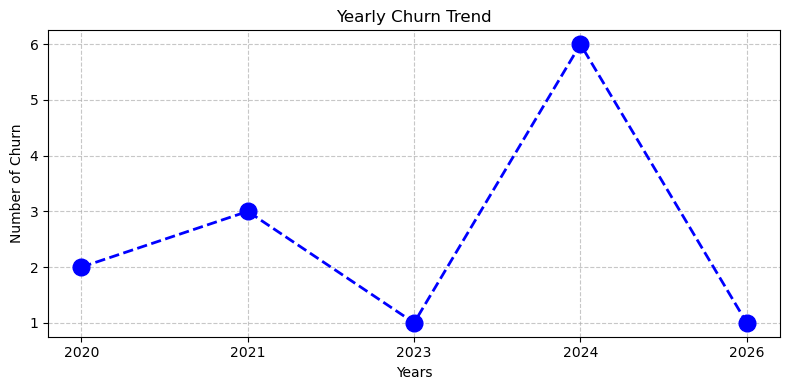

In [437]:
#Yearly churn trend
df_visual['cancellation_year'] = df_visual['cancellation_date'].dt.to_period('Y')
churn_trend_yearly = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_year').size()

plt.figure(figsize=(8, 4))

plt.plot(churn_trend_yearly.index.astype(str), churn_trend_yearly.values, 
         color='blue', marker='o', linestyle='dashed', linewidth=2, markersize=12)
plt.title('Yearly Churn Trend')
plt.ylabel('Number of Churn')
plt.xlabel('Years')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

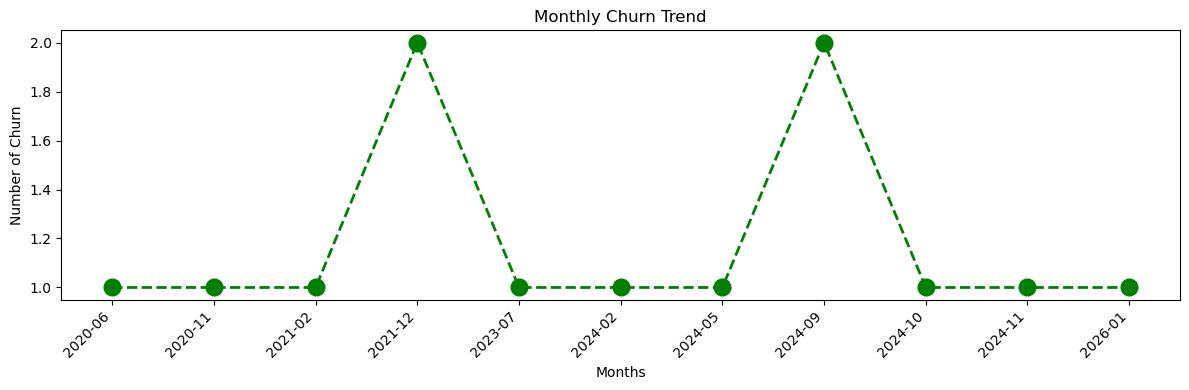

In [400]:
# Monthly Churn trend
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(12, 4))

plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12)
plt.title('Monthly Churn Trend')
plt.ylabel('Number of Churn')
plt.xlabel('Months')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

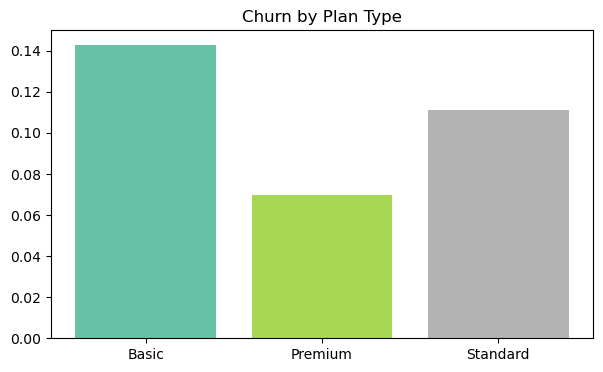

In [429]:
#Churn by plan type
plan_churn = df_visual.groupby('plan_type')['churn_flag'].mean()
plt.figure(figsize=(7,4))
plt.title('Churn by Plan Type')
colors = plt.cm.Set2(np.linspace(0, 1, len(plan_churn)))
plt.bar(plan_churn.index, plan_churn.values, color = colors)
plt.show()

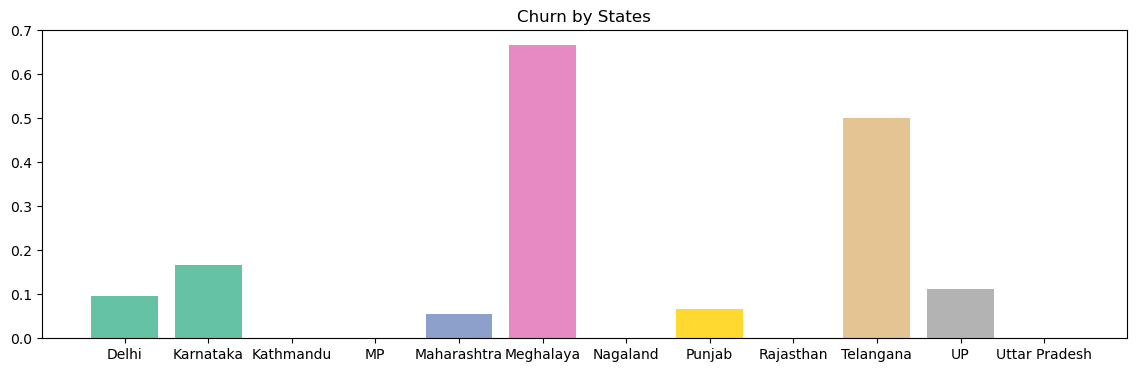

In [402]:
#churn by States
plan_churn = df_visual.groupby('state')['churn_flag'].mean()
plt.figure(figsize=(14,4))
plt.title('Churn by States')
colors = plt.cm.Set2(np.linspace(0, 1, len(plan_churn)))
plt.bar(plan_churn.index, plan_churn.values, color = colors)
plt.show()

In [ ]:
# Visualization by seaborn 

In [403]:
import warnings
warnings.filterwarnings("ignore")

In [430]:
#Encoding - str to int type
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score','churn_flag', 'escalations','churn_risk']]
order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk' : ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded [col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [438]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,1,1,12,0,0,0
1,2,1,91,1,1,2
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,1,2


In [439]:
df_visual[['plan_type', 'contract_type', 'churn_score','churn_flag', 'escalations','churn_risk']].head()

,plan_type,contract_type,churn_score,churn_flag,escalations,churn_risk
0,Standard,Annual,12,0,0,low
1,Premium,Annual,91,1,1,high
2,Basic,Monthly,34,0,0,low
3,Premium,Annual,8,0,0,low
4,Standard,Monthly,88,1,1,high


<Axes: >

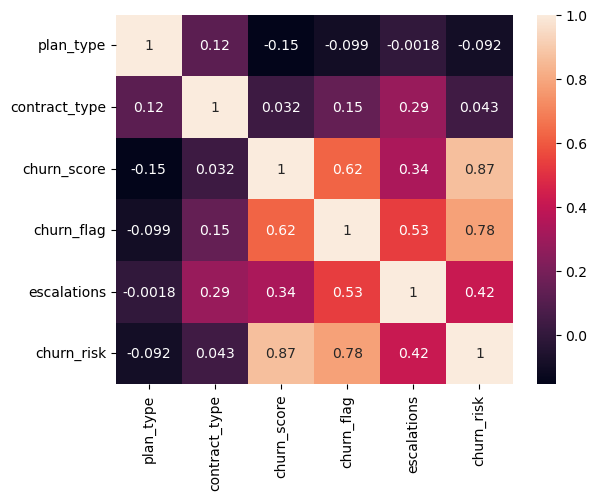

In [440]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot = True)

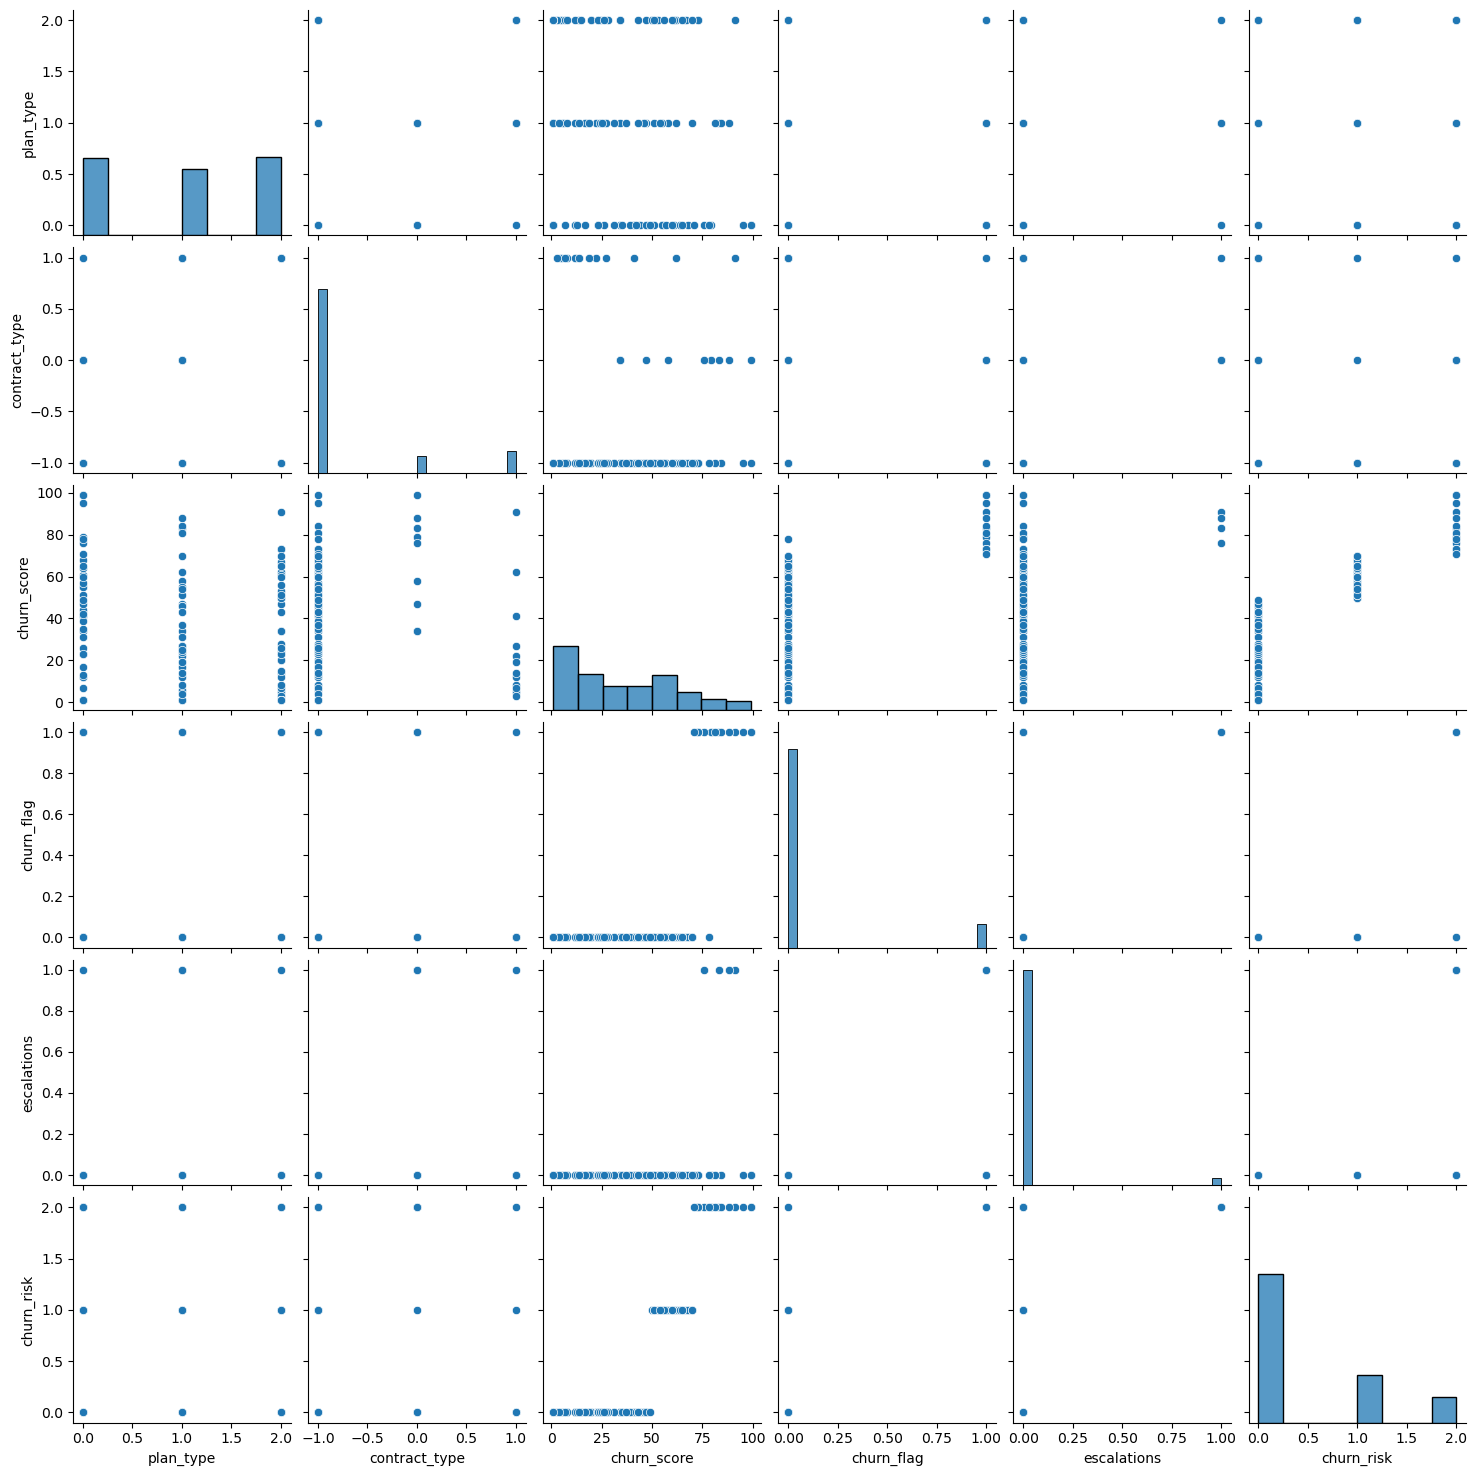

In [408]:
#pair-plot
sns.pairplot(df_encoded)

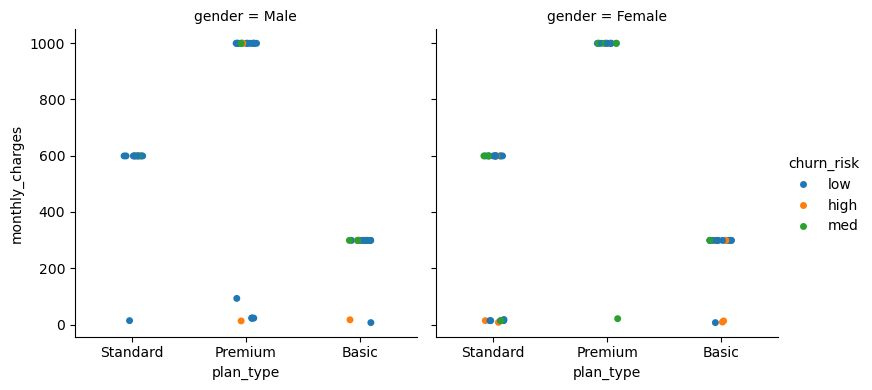

In [409]:
#catplot / facegrid - Multi dimension comparison
sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='churn_risk',
    col='gender',
    height = 4)

In [410]:
#pivot table
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_year', 'cancellation_month'],
      dtype='object')

In [434]:
pd.pivot_table(
    df_visual,
    values= ['churn_flag', 'customerid','monthly_charges','tenure_days'],
    index= 'subscription_type',
    aggfunc = {
        'churn_flag' : 'mean',
        'customerid' : 'nunique',
        'monthly_charges' : 'sum',
        'tenure_days' : 'mean'    }
).reset_index()

,subscription_type,churn_flag,customerid,monthly_charges,tenure_days
0,Organic,0.000000,9,145.91,1701.00
1,Paid,0.166667,6,174.94,1878.50
2,Refferal,0.833333,6,74.94,850.50
3,Streaming,0.070000,100,63200.00,1590.08


In [435]:
pd.pivot_table(
    df_visual,
    values= ['churn_flag', 'customerid','monthly_charges','tenure_days'],
    index= 'plan_type',
    aggfunc = {
        'churn_flag' : 'mean',
        'customerid' : 'nunique',
        'monthly_charges' : 'sum',
        'tenure_days' : 'mean'    }
).reset_index()

,plan_type,churn_flag,customerid,monthly_charges,tenure_days
0,Basic,0.142857,42,11115.95,1528.976190
1,Premium,0.069767,43,36182.93,1726.093023
2,Standard,0.111111,36,16296.91,1451.444444


In [436]:
pd.pivot_table(
    df_visual,
    values= ['churn_flag', 'customerid','monthly_charges','tenure_days'],
    index= 'contract_type',
    aggfunc = {
        'churn_flag' : 'mean',
        'customerid' : 'nunique',
        'monthly_charges' : 'sum',
        'tenure_days' : 'mean'    }
).reset_index()

,contract_type,churn_flag,customerid,monthly_charges,tenure_days
0,Annual,0.083333,12,285.88,1965.916667
1,Month-to-month,0.140000,50,32250.00,1477.000000
2,Monthly,0.555556,9,109.91,899.111111
3,One year,0.000000,30,19970.00,1806.666667
4,Two year,0.000000,20,10980.00,1547.900000
